# Tech Layoffs Analysis (2020-2026)
**Question:** Which companies, industries, countries and funding stages were hit hardest by tech layoffs, and which companies shut down completely?
**Data:** Kaggle "Layoffs Dataset" (swaptr), sourced from layoffs.fyi. 4,615 records, 11 columns.
**Tools:** Python, pandas, matplotlib.

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 

df=pd.read_csv("layoffs.csv")
df.head()

,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added
0,Thinkific,"Vancouver, Non-U.S.",96.0,9/23/2026,NaN,Education,https://investors.thinkific.com/2026-09-23-Thi...,Post-IPO,22.0,Canada,9/24/2026
1,Intel,Sacramento,52.0,9/23/2026,NaN,Hardware,https://www.kron4.com/news/technology-ai/intel...,Post-IPO,12.0,United States,9/23/2026
2,Microsoft,Seattle,500.0,9/22/2026,NaN,Other,https://www.businessinsider.com/microsoft-star...,Post-IPO,1.0,United States,9/23/2026
3,Expedia,Seattle,58.0,9/22/2026,NaN,Travel,https://www.geekwire.com/2026/expedia-group-la...,Post-IPO,3300.0,United States,9/26/2026
4,Apple,SF Bay Area,NaN,9/21/2026,NaN,Hardware,https://www.bloomberg.com/news/newsletters/202...,Post-IPO,1200.0,United States,9/22/2026


In [2]:
df.shape

(4615, 11)

In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4615 entries, 0 to 4614
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   company              4615 non-null   str    
 1   location             4614 non-null   str    
 2   total_laid_off       3015 non-null   float64
 3   date                 4615 non-null   str    
 4   percentage_laid_off  2887 non-null   float64
 5   industry             4613 non-null   str    
 6   source               4612 non-null   str    
 7   stage                4607 non-null   str    
 8   funds_raised         4065 non-null   float64
 9   country              4613 non-null   str    
 10  date_added           4615 non-null   str    
dtypes: float64(3), str(8)
memory usage: 396.7 KB


In [4]:
df.isnull().sum()

company                   0
location                  1
total_laid_off         1600
date                      0
percentage_laid_off    1728
industry                  2
source                    3
stage                     8
funds_raised            550
country                   2
date_added                0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
layoffs_df=df.copy()

In [7]:
cols=["company","location","date","total_laid_off","stage","country"]
layoffs_df.duplicated(subset=cols).sum()

np.int64(4)

In [8]:
layoffs_df=layoffs_df.drop_duplicates(subset=cols)
layoffs_df.duplicated(subset=cols).sum()

np.int64(0)

In [9]:
layoffs_df["date"]=pd.to_datetime(layoffs_df["date"])
layoffs_df["date_added"]=pd.to_datetime(layoffs_df["date_added"])
layoffs_df["year"]=layoffs_df["date"].dt.year
layoffs_df["month"]=layoffs_df["date"].dt.month

In [10]:
for c in ["company","location","industry","stage","country"]:
    layoffs_df[c]=layoffs_df[c].str.strip()
   
    

In [11]:
 layoffs_df["industry"].unique()


<StringArray>
[     'Education',       'Hardware',          'Other',         'Travel',
         'Energy',        'Finance',         'Crypto',       'Consumer',
     'Healthcare',      'Marketing',       'Security', 'Transportation',
           'Food',         'Retail',        'Product',  'Manufacturing',
      'Aerospace',           'Data',          'Media',     'Recruiting',
          'Sales',          'Legal',    'Real Estate', 'Infrastructure',
             'AI',        'Support',             'HR',      'Logistics',
        'Fitness',              nan,   'Construction']
Length: 31, dtype: str

In [12]:
layoffs_df["country"].unique()

<StringArray>
[              'Canada',        'United States',               'Sweden',
                'India',          'Switzerland',               'Poland',
            'Australia',               'Israel',              'Germany',
                'Chile',              'Ireland',              'Nigeria',
                  'UAE',            'Singapore',       'United Kingdom',
           'Seychelles',       'Cayman Islands',          'Netherlands',
               'Brazil',            'Indonesia',              'Austria',
              'Denmark',               'Norway',                'Egypt',
 'United Arab Emirates',              'Estonia',                'Kenya',
               'Cyprus',          'New Zealand',       'Czech Republic',
               'Turkey',              'Uruguay',                'Japan',
             'Portugal',               'France',                'Malta',
                'China',             'Pakistan',                'Spain',
              'Belgium',            '

In [13]:
layoffs_df["country"] = layoffs_df["country"].replace({"UAE": "United Arab Emirates"})

In [14]:
sorted(layoffs_df["country"].dropna().unique())

['Argentina',
 'Australia',
 'Austria',
 'Bahrain',
 'Belgium',
 'Brazil',
 'Bulgaria',
 'Canada',
 'Cayman Islands',
 'Chile',
 'China',
 'Colombia',
 'Cyprus',
 'Czech Republic',
 'Denmark',
 'Egypt',
 'Estonia',
 'Finland',
 'France',
 'Germany',
 'Ghana',
 'Greece',
 'Hong Kong',
 'Hungary',
 'India',
 'Indonesia',
 'Ireland',
 'Israel',
 'Italy',
 'Japan',
 'Kenya',
 'Lithuania',
 'Luxembourg',
 'Malaysia',
 'Malta',
 'Mexico',
 'Myanmar',
 'Netherlands',
 'New Zealand',
 'Nigeria',
 'Norway',
 'Pakistan',
 'Peru',
 'Philippines',
 'Poland',
 'Portugal',
 'Romania',
 'Russia',
 'Saudi Arabia',
 'Senegal',
 'Seychelles',
 'Singapore',
 'South Africa',
 'South Korea',
 'Spain',
 'Sweden',
 'Switzerland',
 'Thailand',
 'Turkey',
 'Ukraine',
 'United Arab Emirates',
 'United Kingdom',
 'United States',
 'Uruguay',
 'Vietnam']

In [15]:
for c in ["industry","stage","country","location"]:
    layoffs_df[c] = layoffs_df[c].fillna("Unknown")
layoffs_df.isnull().sum()

company                   0
location                  0
total_laid_off         1600
date                      0
percentage_laid_off    1728
industry                  0
source                    3
stage                     0
funds_raised            550
country                   0
date_added                0
year                      0
month                     0
dtype: int64

In [16]:
layoffs_df["year"].value_counts().sort_index()

year
2020     635
2021      44
2022    1228
2023    1389
2024     634
2025     333
2026     348
Name: count, dtype: int64

## Cleaning Log
- Checked full-row duplicates: 0. Checked again on company, location, date, total laid off, stage and country: found 4 hidden duplicates and removed them.
- Converted date and date_added from text to dates; added year and month columns.
- Trimmed extra spaces in text columns.
- Merged "UAE" into "United Arab Emirates".
- Filled missing industry, stage, country and location with "Unknown".
- Left total_laid_off (1,600 missing), percentage_laid_off (1,728 missing) and funds_raised (550 missing) empty on purpose.
Filling them with 0 or an average would invent data.

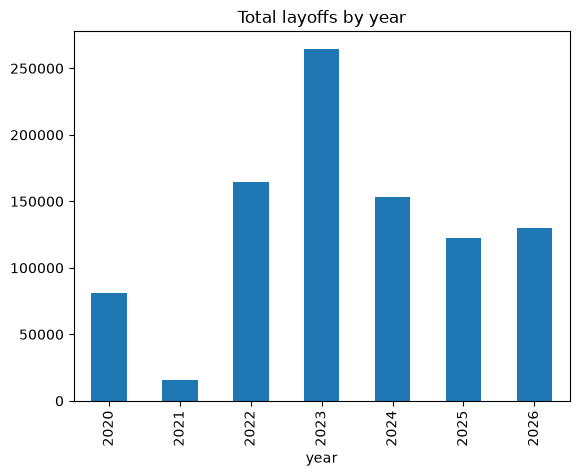

In [17]:
#Layoffs by year.
yearly = layoffs_df.groupby("year")["total_laid_off"].sum()
yearly.plot(kind="bar", title="Total layoffs by year")
plt.savefig("layoffs_by_year.png", bbox_inches="tight")

**Insight:** Layoffs peaked in 2023 at about 264,000 jobs, up from about 164,000 in 2022.
They fell to about 153,000 in 2024 and about 122,000 in 2025. 2026 (about 130,000) only covers the data up to September, so it is a partial year.
2021 is very low (about 16,000), which is when hiring boomed.

<Axes: title={'center': 'Layoffs by month'}, xlabel='date'>

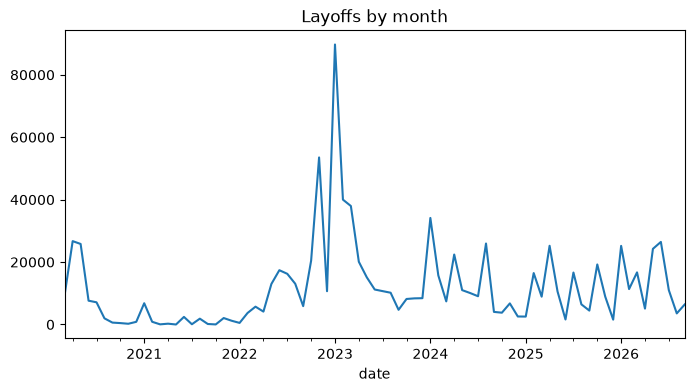

In [18]:
#Monthly trend.

monthly = layoffs_df.groupby(layoffs_df["date"].dt.to_period("M"))["total_laid_off"].sum()
monthly.plot(figsize=(8,4), title="Layoffs by month")

**Insight:** One month stands out: January 2023, with about 90,000 layoffs, after a smaller spike in November 2022 (about 53,000).
Since 2024 the pattern is smaller spikes of 20,000 to 35,000, often at the start of a year.

<Axes: ylabel='industry'>

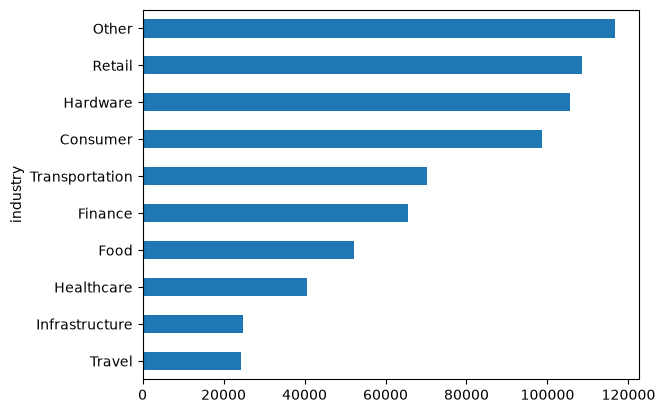

In [19]:
#3  Top 10 industries and countries.

layoffs_df.groupby("industry")["total_laid_off"].sum().nlargest(10).sort_values().plot(kind="barh")

**Insight:** "Other" is the largest group (about 116,000), but it is a catch-all category.
Among named industries, Retail (about 108,000) and Hardware (about 105,000) lost the most jobs, followed by Consumer (about 98,000).

<Axes: ylabel='country'>

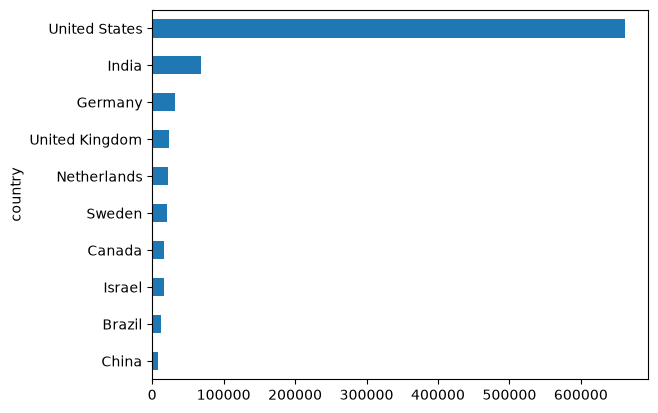

In [20]:
layoffs_df.groupby("country")["total_laid_off"].sum().nlargest(10).sort_values().plot(kind="barh")

**Insight:** The United States dominates with about 660,000 layoffs, roughly 70% of the total. 
India is second (about 67,000), then Germany (about 31,000).
The data mostly reflects US tech companies, so global conclusions need care.

<Axes: ylabel='company'>

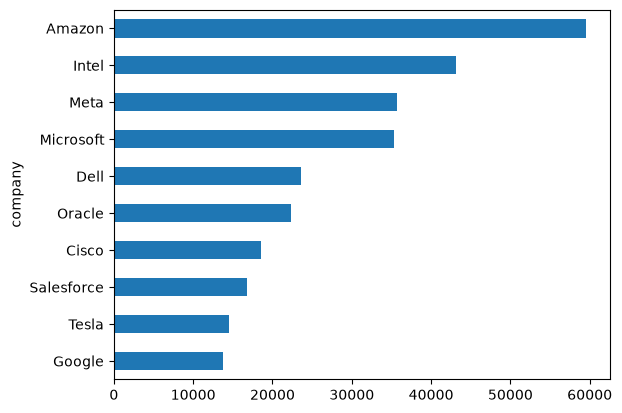

In [21]:
#4 Top 10 companies.

layoffs_df.groupby("company")["total_laid_off"].sum().nlargest(10).sort_values().plot(kind="barh")

**Insight:** Amazon is far ahead with about 59,000 layoffs, then Intel (about 43,000), and Meta and Microsoft (about 36,000 each).
Big, well-known companies drive most of the headline numbers.

<Axes: ylabel='stage'>

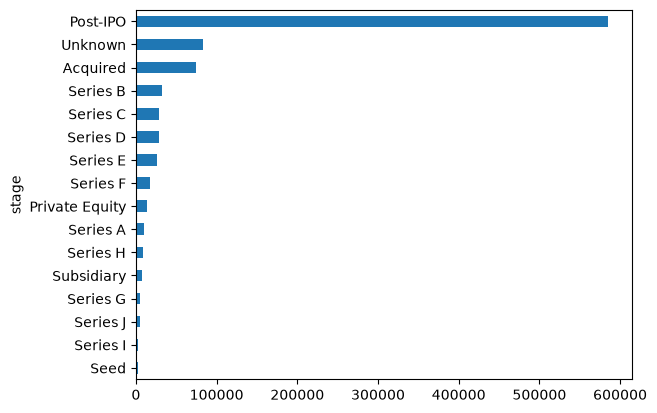

In [22]:
#5 Funding and shutdowns.

layoffs_df.groupby("stage")["total_laid_off"].sum().sort_values().plot(kind="barh")

**Insight:** Post-IPO (public) companies have the most layoffs overall, followed by Acquired and Unknown.
Large, mature companies cut the most jobs in total.


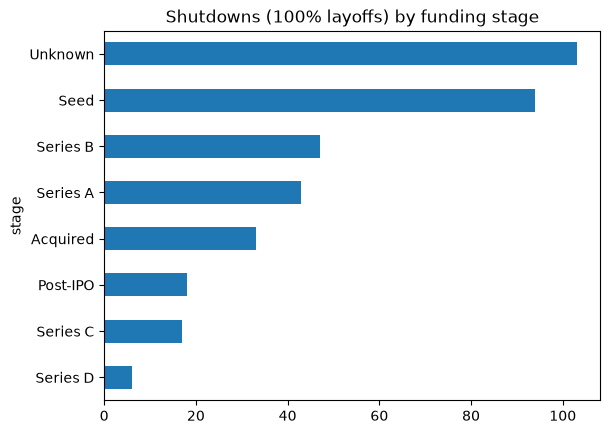

In [23]:
shutdowns = layoffs_df[layoffs_df["percentage_laid_off"] == 1]
shutdowns["stage"].value_counts().head(8).sort_values().plot(kind="barh", title="Shutdowns (100% layoffs) by funding stage")
plt.show()

In [24]:
layoffs_df[layoffs_df["percentage_laid_off"] == 1].shape[0]

374

**Insight:** 374 records show a 100% layoff.
Seed, Series A and Series B companies make up about half of them (roughly 94 + 43 + 47), while Post-IPO companies account for only about 18. 
Big`m companies cut the most jobs in total, but small early-stage startups are the ones that shut down completely. 
About 100 more have an unknown stage, which is a data gap.

In [25]:
layoffs_df.to_csv("layoffs_clean.csv", index=False)

## Conclusion
1. Layoffs peaked in 2023 (about 264,000), with January 2023 the worst single month (about 90,000).
2. The US accounts for about 70% of all layoffs.
3. Amazon, Intel, Meta and Microsoft lead by company, and Retail and Hardware lead by industry.
4. Large public companies cut the most jobs in total, while early-stage startups (Seed to Series B) are about half of all complete shutdowns.

## Limitations
- About 1,600 rows have no layoff count, so all totals are undercounts.
- A 100% layoff suggests a shutdown, but it may also mean a single office or team was closed.
- The data is dominated by US companies, and 2026 is a partial year.

In [26]:
import os
[f for f in os.listdir() if "layoffs" in f.lower()]

['layoffs.csv', 'layoffs.ipynb', 'layoffs_by_year.png', 'layoffs_clean.csv']